# Home Fire & Smoke Detection with YOLO


## 1. Introduction

Fire is easiest to stop in its first few seconds, and that is exactly the part a person
watching a monitor tends to miss - a small flame at the edge of frame, or a thin line of
smoke against a bright ceiling. The point of this project is a model that watches camera
frames and raises the flag itself.

YOLO ("You Only Look Once") runs detection in a single pass over the image, which is what
makes it fast enough for live video. For every object it finds it returns a bounding box, a
class label and a confidence between 0 and 1.

Rather than training from scratch, we fine-tune `yolo11n.pt` - YOLO11-nano, already trained
on millions of general images - so it only has to learn our two classes.

### The dataset

[Home Fire Dataset](https://www.kaggle.com/datasets/pengbo00/home-fire-dataset) from Kaggle.

| Property | Value |
|---|---|
| Format | YOLO TXT - one `.txt` per image, lines of `class cx cy w h` (normalised 0-1) |
| Classes | 2 - `0: fire`, `1: smoke` |
| Train / val / test | 3,900 / 1,300 / 1,300 images |
| Bounding boxes | 7,978 (fire 4,838, smoke 3,140) |
| Empty label files | 135 - background images, which is normal in YOLO |
| Missing labels, corrupt images, invalid boxes | 0 |
| Byte-identical images across splits | 0 |
| Near-identical frames across splits | roughly a third - see the note |



## 2. Install dependencies


In [1]:
# --- Install only the packages that are missing -----------------------------
import sys, subprocess, importlib.util

def _have(mod):
    return importlib.util.find_spec(mod) is not None

# (import-name, pip-requirement)
NEEDED = [
    ("ultralytics", "ultralytics>=8.3.0,<9.0.0"),
    ("cv2",         "opencv-python>=4.8.0"),
    ("numpy",       "numpy>=1.26.0,<3.0.0"),
    ("pandas",      "pandas>=2.0.0"),
    ("matplotlib",  "matplotlib>=3.7.0"),
    ("yaml",        "pyyaml>=6.0"),
    ("PIL",         "pillow>=10.0.0"),
]

to_install = [req for mod, req in NEEDED if not _have(mod)]
if not _have("torch"):
    to_install += ["torch>=2.2.0", "torchvision>=0.17.0"]

if to_install:
    print("Installing:", to_install)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *to_install])
    print("Install finished.")
else:
    print("All dependencies already present - nothing to install.")

# --- Verify the imports we rely on ------------------------------------------
import torch, ultralytics, cv2, numpy as np, pandas as pd, matplotlib, yaml, PIL
print(f"torch         : {torch.__version__}")
print(f"ultralytics   : {ultralytics.__version__}")
print(f"opencv (cv2)  : {cv2.__version__}")
print(f"numpy         : {np.__version__}")
print(f"pandas        : {pd.__version__}")
print(f"matplotlib    : {matplotlib.__version__}")
print(f"pyyaml        : {yaml.__version__}")
print(f"pillow (PIL)  : {PIL.__version__}")
print("CUDA available :", torch.cuda.is_available())


All dependencies already present - nothing to install.
torch         : 2.14.1+cpu
ultralytics   : 8.4.177
opencv (cv2)  : 5.0.0
numpy         : 2.2.0
pandas        : 3.0.5
matplotlib    : 3.11.1
pyyaml        : 6.0.3
pillow (PIL)  : 12.3.0
CUDA available : False


## 3. Configure paths & training settings



In [ ]:
import os, sys, glob, json, time, random, shutil, hashlib, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from PIL import Image
import cv2
import torch

# %matplotlib inline  # (uncomment if plots do not render in your Jupyter UI)

# ---- Reproducibility ----
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# ---- Environment detection (Google Colab vs local / VS Code Jupyter) ----
IS_COLAB   = "google.colab" in sys.modules
IS_KAGGLE  = os.path.exists("/kaggle/input")
ENV_NAME   = "Google Colab" if IS_COLAB else ("Kaggle" if IS_KAGGLE else "Local / VS Code Jupyter")

# ---- Project root ----
if IS_COLAB:
    PROJECT_ROOT = Path("/content/Home_Fire_YOLO")
else:
    PROJECT_ROOT = Path.cwd()
    if (PROJECT_ROOT / "Home_Fire_YOLO").is_dir():        # launched from the parent dir
        PROJECT_ROOT = PROJECT_ROOT / "Home_Fire_YOLO"

# ---- Key paths ----
ZIP_PATH   = None          # e.g. r"C:\Users\you\Downloads\archive.zip"  (None = auto-search)
DATA_DIR   = PROJECT_ROOT / "data" / "home_fire"          # where the ZIP is extracted
CONFIG_DIR = PROJECT_ROOT / "configs"
MODELS_DIR = PROJECT_ROOT / "models"
RUNS_DIR   = PROJECT_ROOT / "runs"                        # Ultralytics training output
PRED_DIR   = PROJECT_ROOT / "outputs" / "predictions"
REPORT_DIR = PROJECT_ROOT / "outputs" / "reports"
DATA_YAML  = CONFIG_DIR / "data.yaml"

# ---- Model & training settings ----
MODEL_NAME  = "yolo11n.pt"   # pretrained YOLO11-nano (auto-downloaded on first use)
EPOCHS      = 50             # training epochs
IMG_SIZE    = 640            # image size
BATCH_SIZE  = 8              # batch size
WORKERS     = 4              # DataLoader workers (set 0 if you hit Windows DataLoader issues)
PATIENCE    = 15             # early-stopping patience (epochs)
CONF_THRESH = 0.25           # default confidence threshold for inference

# ---- Explicit training gate: training runs ONLY when this is True ----
RUN_TRAINING = True

# ---- Class names (confirmed by visually inspecting annotated samples) ----
# Class 0 boxes enclose fire; class 1 boxes enclose smoke. The Kaggle data card
# also lists them as "flame / smoke". I renamed flame to fire, since that is
# how the class is reported everywhere else.
CLASS_NAMES = {0: "fire", 1: "smoke"}

# ---- Create project folders ----
for _d in [DATA_DIR, CONFIG_DIR, MODELS_DIR, RUNS_DIR, PRED_DIR, REPORT_DIR]:
    _d.mkdir(parents=True, exist_ok=True)

# ---- Device: use GPU if available, otherwise CPU ----
DEVICE = "0" if torch.cuda.is_available() else "cpu"

print("Environment     :", ENV_NAME)
print("Platform        :", platform.platform())
print("PROJECT_ROOT    :", PROJECT_ROOT)
print("DATA_DIR        :", DATA_DIR, "(exists)" if DATA_DIR.exists() else "(created on extraction)")
print("DATA_YAML       :", DATA_YAML)
print("RUNS_DIR        :", RUNS_DIR)
print("Device          :", DEVICE, "(GPU)" if DEVICE != "cpu" else "(CPU fallback)")
print("Model           :", MODEL_NAME)
print("Epochs/Size/Batch:", EPOCHS, "/", IMG_SIZE, "/", BATCH_SIZE, "| Seed:", SEED)
print("Classes         :", CLASS_NAMES)
print("RUN_TRAINING    :", RUN_TRAINING, "<- training is OFF" if not RUN_TRAINING else "<- training is ON")


Environment     : Local / VS Code Jupyter
Platform        : Windows-11-10.0.26200-SP0
PROJECT_ROOT    : Home_Fire_YOLO
DATA_DIR        : Home_Fire_YOLO\data\home_fire (exists)
DATA_YAML       : Home_Fire_YOLO\configs\data.yaml
RUNS_DIR        : Home_Fire_YOLO\runs
Device          : cpu (CPU fallback)
Model           : yolo11n.pt
Epochs/Size/Batch: 50 / 640 / 8 | Seed: 42
Classes         : {0: 'flame', 1: 'smoke'}
RUN_TRAINING    : True <- training is ON


## 3b. Locate & extract the dataset


In [3]:
import zipfile

def find_zip(zip_path=None):
    """Locate the dataset ZIP in common locations. Returns a Path or None."""
    candidates = []
    if zip_path:
        candidates.append(Path(zip_path))
    if IS_COLAB:
        candidates += sorted(Path("/content").glob("*.zip"))
        candidates += sorted(Path("/kaggle/input").glob("**/*.zip"))
    # Common local spots
    candidates += [
        Path.home() / "Downloads" / "archive.zip",
        PROJECT_ROOT / "archive.zip",
        PROJECT_ROOT.parent / "archive.zip",
        Path.cwd() / "archive.zip",
    ]
    candidates += sorted(Path.cwd().glob("*.zip"))
    seen = set()
    for c in candidates:
        try:
            c = c.resolve()
        except Exception:
            continue
        if c in seen:
            continue
        seen.add(c)
        if c.is_file():
            return c
    return None

def extract_dataset(zip_path, dest_dir, force=False):
    """Extract zip_path into dest_dir (copy only; the original ZIP is untouched)."""
    zip_path, dest_dir = Path(zip_path), Path(dest_dir)
    expected = [dest_dir / s / "images" for s in ("train", "val", "test")]
    if all(p.is_dir() for p in expected) and not force:
        print(f"Dataset already extracted at: {dest_dir}  -> skipping extraction.")
        return dest_dir
    dest_dir.mkdir(parents=True, exist_ok=True)
    size_mb = zip_path.stat().st_size / 1e6
    print(f"Extracting {zip_path.name} ({size_mb:.1f} MB) -> {dest_dir}")
    t0 = time.time()
    with zipfile.ZipFile(zip_path, "r") as zf:
        # Guard against path traversal outside dest_dir
        for member in zf.namelist():
            target = (dest_dir / member).resolve()
            if not str(target).startswith(str(dest_dir.resolve())):
                raise RuntimeError(f"Unsafe path in archive: {member}")
        zf.extractall(dest_dir)
        # Handle any nested archives one level deep (e.g. train.zip inside)
        nested = [m for m in zf.namelist() if m.lower().endswith((".zip",))]
    for nz in sorted(dest_dir.rglob("*.zip")):
        print("  extracting nested archive:", nz.name)
        with zipfile.ZipFile(nz, "r") as zf2:
            zf2.extractall(nz.parent)
    print(f"Done in {time.time()-t0:.1f}s.")
    return dest_dir

ZIP_FILE = find_zip(ZIP_PATH)
if ZIP_FILE is None:
    print("ERROR: could not find the dataset ZIP.")
    print("  -> Place 'archive.zip' in your Downloads folder or in the project folder,")
    print("     or set ZIP_PATH in the 'Configure paths' cell to its full path, e.g.:")
    print(r'       ZIP_PATH = r"C:\Users\you\Downloads\archive.zip"')
else:
    print("Found ZIP:", ZIP_FILE)
    extract_dataset(ZIP_FILE, DATA_DIR)

# Quick confirmation of the on-disk layout
for sp in ["train", "val", "test"]:
    img_dir = DATA_DIR / sp / "images"
    lbl_dir = DATA_DIR / sp / "labels"
    n_img = len(list(img_dir.glob("*"))) if img_dir.is_dir() else 0
    n_lbl = len(list(lbl_dir.glob("*.txt"))) if lbl_dir.is_dir() else 0
    print(f"  {sp:5s}: images={n_img:5d}  labels={n_lbl:5d}")


Found ZIP: archive.zip
Dataset already extracted at: Home_Fire_YOLO\data\home_fire  -> skipping extraction.
  train: images= 3900  labels= 3900
  val  : images= 1300  labels= 1300
  test : images= 1300  labels= 1300


## 4. Dataset exploration



In [4]:
SPLITS   = ["train", "val", "test"]
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def list_split(split):
    """Return (images, labels, img_dir, lbl_dir) for a split, sorted by name."""
    img_dir = DATA_DIR / split / "images"
    lbl_dir = DATA_DIR / split / "labels"
    imgs = sorted([p for p in img_dir.iterdir() if p.suffix.lower() in IMG_EXTS]) if img_dir.is_dir() else []
    lbls = sorted(lbl_dir.glob("*.txt")) if lbl_dir.is_dir() else []
    return imgs, lbls, img_dir, lbl_dir

def parse_label_file(path):
    """Parse a YOLO .txt into a list of token-lists (one per non-empty line)."""
    rows = []
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if line:
                rows.append(line.split())
    return rows

# ---- Scan every split ----
scan = {}
all_class_ids = set()
dim_counter = {}
for sp in SPLITS:
    imgs, lbls, img_dir, lbl_dir = list_split(sp)
    img_stems = {p.stem for p in imgs}
    lbl_stems = {p.stem for p in lbls}
    missing_lbl = sorted(img_stems - lbl_stems)
    orphan_lbl  = sorted(lbl_stems - img_stems)
    empty_lbl, boxes_per_cls, files_per_cls = 0, {}, {}
    for lp in lbls:
        rows = parse_label_file(lp)
        if not rows:
            empty_lbl += 1
            continue
        seen = set()
        for parts in rows:
            cid = int(float(parts[0]))
            all_class_ids.add(cid)
            boxes_per_cls[cid] = boxes_per_cls.get(cid, 0) + 1
            seen.add(cid)
        for cid in seen:
            files_per_cls[cid] = files_per_cls.get(cid, 0) + 1
    # Sample dimensions (sample up to 400 images per split for speed)
    step = max(1, len(imgs) // 400)
    for ip in imgs[::step]:
        try:
            with Image.open(ip) as im:
                w, h = im.size
            key = f"{w}x{h}"
            dim_counter[key] = dim_counter.get(key, 0) + 1
        except Exception:
            pass
    scan[sp] = dict(images=len(imgs), labels=len(lbls), missing_labels=len(missing_lbl),
                    orphan_labels=len(orphan_lbl), empty_label_files=empty_lbl,
                    boxes_per_class=boxes_per_cls, files_per_class=files_per_cls,
                    _missing=missing_lbl, _orphan=orphan_lbl,
                    img_dir=str(img_dir), lbl_dir=str(lbl_dir))

print("=" * 68)
print("DATASET EXPLORATION")
print("=" * 68)
total_img = 0
for sp in SPLITS:
    s = scan[sp]
    total_img += s["images"]
    print(f"\n[{sp}]")
    print(f"   images              : {s['images']}")
    print(f"   labels              : {s['labels']}")
    print(f"   missing labels      : {s['missing_labels']}")
    print(f"   orphan labels       : {s['orphan_labels']}")
    print(f"   empty label files   : {s['empty_label_files']}  (background images)")
    print(f"   boxes per class     : {s['boxes_per_class']}")
    print(f"   images per class    : {s['files_per_class']}")
print(f"\nTotal images           : {total_img}")
print("Detected class IDs     :", sorted(all_class_ids))
print("Expected class names   :", CLASS_NAMES)
print("\nCommon image sizes (sampled):")
for k, v in sorted(dim_counter.items(), key=lambda kv: -kv[1])[:6]:
    print(f"   {k:>12s} : {v}")

# Persist the exploration summary for later reuse
EXPLORATION = dict(total_images=total_img, class_ids=sorted(all_class_ids), scan=scan)


DATASET EXPLORATION

[train]
   images              : 3900
   labels              : 3900
   missing labels      : 0
   orphan labels       : 0
   empty label files   : 87  (background images)
   boxes per class     : {0: 2978, 1: 1834}
   images per class    : {0: 2763, 1: 1717}

[val]
   images              : 1300
   labels              : 1300
   missing labels      : 0
   orphan labels       : 0
   empty label files   : 33  (background images)
   boxes per class     : {0: 963, 1: 617}
   images per class    : {0: 894, 1: 574}

[test]
   images              : 1300
   labels              : 1300
   missing labels      : 0
   orphan labels       : 0
   empty label files   : 15  (background images)
   boxes per class     : {1: 689, 0: 897}
   images per class    : {1: 618, 0: 852}

Total images           : 6500
Detected class IDs     : [0, 1]
Expected class names   : {0: 'flame', 1: 'smoke'}

Common image sizes (sampled):
       1280x720 : 689
      1920x1080 : 148
        960x540 : 134
 

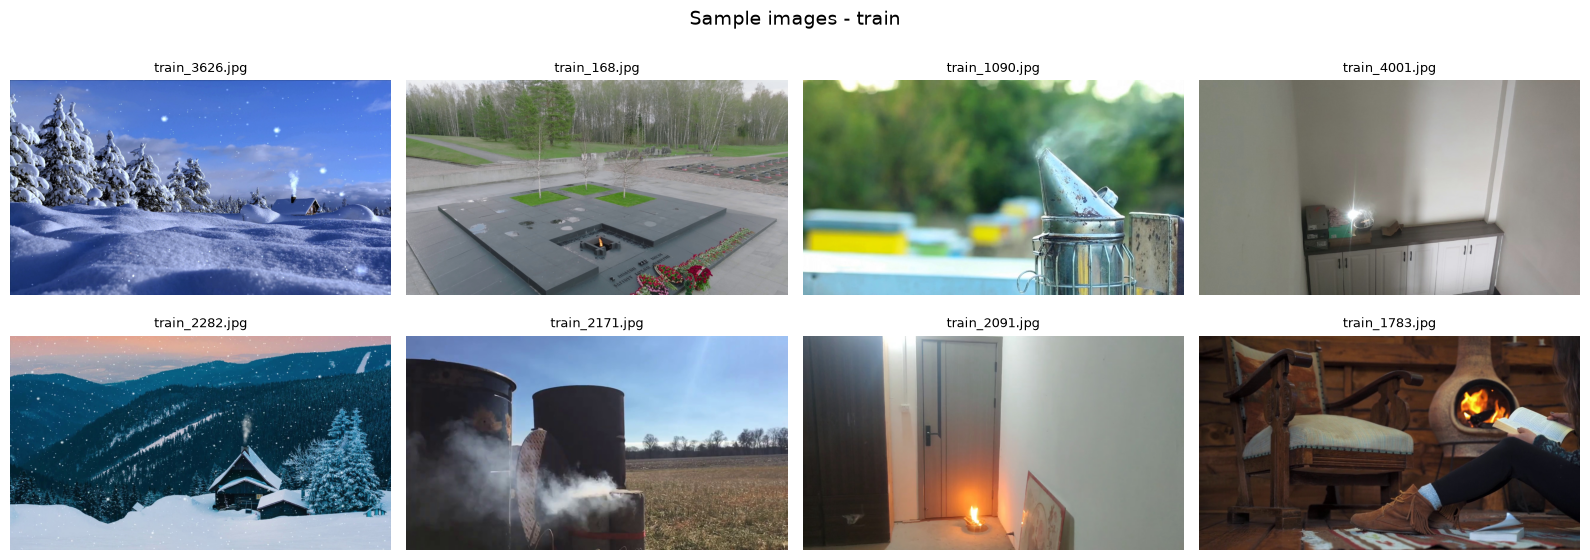

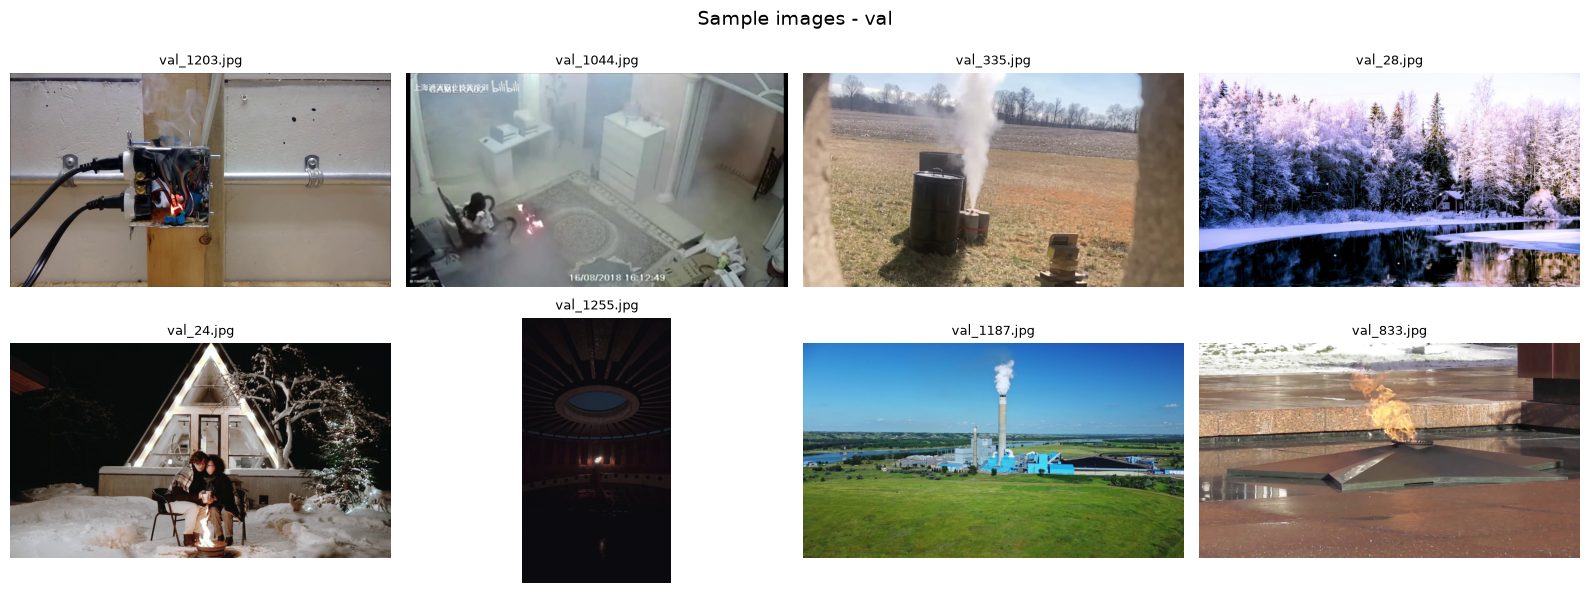

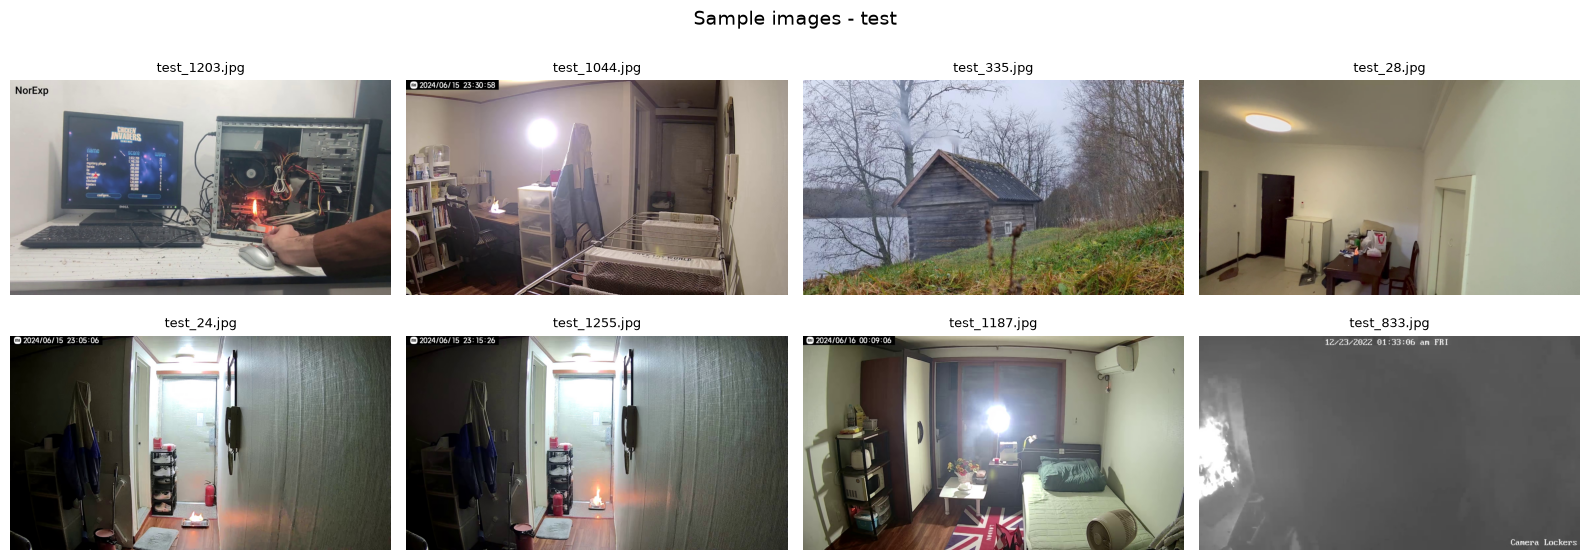

In [5]:
# ---- Display sample images from each split ----
def show_samples(split="train", n=8, seed=SEED):
    imgs, _, _, _ = list_split(split)
    if not imgs:
        print("No images found for split:", split)
        return
    rng = random.Random(seed)
    picks = rng.sample(imgs, min(n, len(imgs)))
    cols = 4
    rows = (len(picks) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 3 * rows))
    axes = np.array(axes).reshape(-1)
    for ax, p in zip(axes, picks):
        try:
            ax.imshow(Image.open(p))
        except Exception as e:
            ax.set_title(f"load error: {e}", fontsize=8)
        ax.set_title(p.name, fontsize=9)
        ax.axis("off")
    for ax in axes[len(picks):]:
        ax.axis("off")
    plt.suptitle(f"Sample images - {split}", fontsize=14)
    plt.tight_layout()
    plt.show()

for sp in ["train", "val", "test"]:
    show_samples(sp, n=8)


## 5. Dataset validation



In [6]:
def validate_split(split):
    """Validate one split. Returns (report_dict, valid_box_count, n_images, n_labels)."""
    imgs, lbls, img_dir, lbl_dir = list_split(split)
    img_stems = {p.stem for p in imgs}
    lbl_stems = {p.stem for p in lbls}
    problems = {"missing_label": [], "orphan_label": [], "bad_class": [],
                "bad_fields": [], "out_of_range": [], "degenerate_box": [],
                "corrupt_image": []}
    valid_boxes = 0
    for lp in lbls:
        for parts in parse_label_file(lp):
            if len(parts) != 5:
                problems["bad_fields"].append((lp.name, " ".join(parts)))
                continue
            try:
                cid = int(float(parts[0]))
                cx, cy, w, h = map(float, parts[1:])
            except ValueError:
                problems["bad_fields"].append((lp.name, " ".join(parts)))
                continue
            if cid not in CLASS_NAMES:
                problems["bad_class"].append((lp.name, cid))
            if not (0 <= cx <= 1 and 0 <= cy <= 1 and 0 <= w <= 1 and 0 <= h <= 1):
                problems["out_of_range"].append((lp.name, f"{cx},{cy},{w},{h}"))
            if w <= 0 or h <= 0:
                problems["degenerate_box"].append((lp.name, f"{w}x{h}"))
            else:
                valid_boxes += 1
    for ip in imgs:
        try:
            with Image.open(ip) as im:
                im.verify()
        except Exception as e:
            problems["corrupt_image"].append((ip.name, str(e)))
    problems["missing_label"] = sorted(img_stems - lbl_stems)
    problems["orphan_label"]  = sorted(lbl_stems - img_stems)
    return problems, valid_boxes, len(imgs), len(lbls)

def hash_file(p):
    h = hashlib.md5()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

# ---- Run validation on all splits ----
VALIDATION = {}
rows = []
all_hashes = {}   # hash -> list of (split, stem)
for sp in SPLITS:
    probs, valid_boxes, n_img, n_lbl = validate_split(sp)
    VALIDATION[sp] = probs
    n_issues = sum(len(v) for v in probs.values())
    rows.append(dict(split=sp, images=n_img, labels=n_lbl, valid_boxes=valid_boxes,
                     missing_labels=len(probs["missing_label"]),
                     orphan_labels=len(probs["orphan_label"]),
                     bad_class=len(probs["bad_class"]),
                     bad_fields=len(probs["bad_fields"]),
                     out_of_range=len(probs["out_of_range"]),
                     degenerate_box=len(probs["degenerate_box"]),
                     corrupt_images=len(probs["corrupt_image"]),
                     total_issues=n_issues))
    # Hash images for duplicate / leakage detection
    imgs, _, _, _ = list_split(sp)
    for ip in imgs:
        try:
            hh = hash_file(ip)
        except Exception:
            continue
        all_hashes.setdefault(hh, []).append((sp, ip.stem))

val_df = pd.DataFrame(rows)
print("=" * 68)
print("VALIDATION REPORT")
print("=" * 68)
print(val_df.to_string(index=False))

# ---- Duplicate & leakage analysis ----
dup_groups = {h: v for h, v in all_hashes.items() if len(v) > 1}
within_dups, cross_split = 0, 0
leak_examples = []
for h, v in dup_groups.items():
    splits = {s for s, _ in v}
    if len(splits) > 1:
        cross_split += 1
        if len(leak_examples) < 10:
            leak_examples.append(v)
    else:
        within_dups += 1

print("\n" + "-" * 68)
print(f"Duplicate image groups (identical content) : {len(dup_groups)}")
print(f"   within a single split                   : {within_dups}")
print(f"   ACROSS splits (potential leakage)       : {cross_split}")
if leak_examples:
    print("   leakage examples (split, stem):")
    for ex in leak_examples:
        print("      ", ex)
print("-" * 68)

# ---- Print any concrete problems found ----
anything = False
for sp in SPLITS:
    for key, items in VALIDATION[sp].items():
        if items:
            if not anything:
                print("\nDetailed issues (first few per category):")
                anything = True
            print(f"  [{sp}] {key}: {len(items)}  e.g. {items[:3]}")
if not anything:
    print("\nNo annotation or image problems detected. Dataset is clean.")


VALIDATION REPORT
split  images  labels  valid_boxes  missing_labels  orphan_labels  bad_class  bad_fields  out_of_range  degenerate_box  corrupt_images  total_issues
train    3900    3900         4812               0              0          0           0             0               0               0             0
  val    1300    1300         1580               0              0          0           0             0               0               0             0
 test    1300    1300         1586               0              0          0           0             0               0               0             0

--------------------------------------------------------------------
Duplicate image groups (identical content) : 2
   within a single split                   : 2
   ACROSS splits (potential leakage)       : 0
--------------------------------------------------------------------

No annotation or image problems detected. Dataset is clean.


## 6. Annotation visualization




Ground-truth samples (flame = red, smoke = blue):


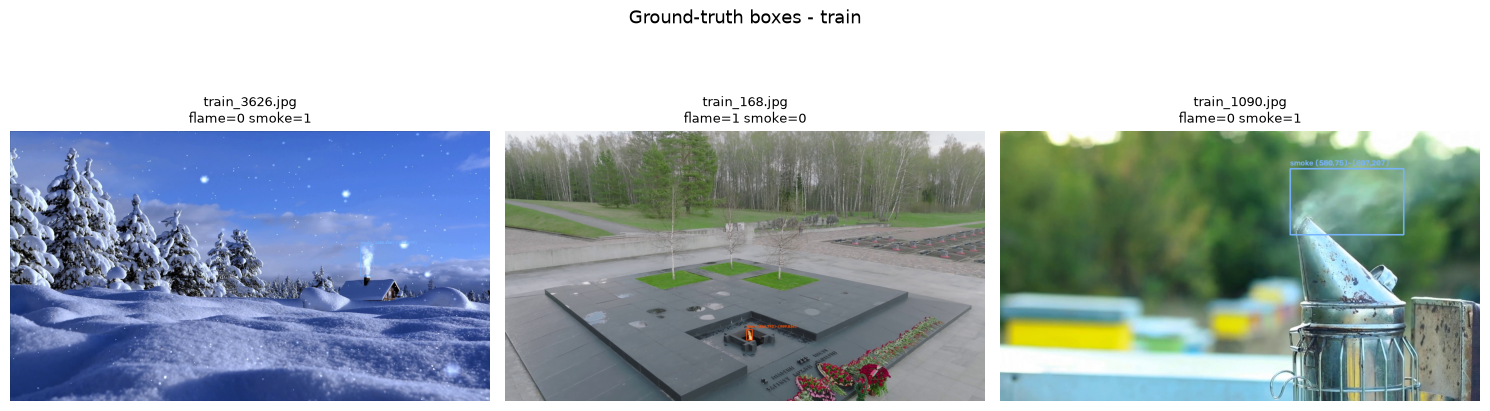

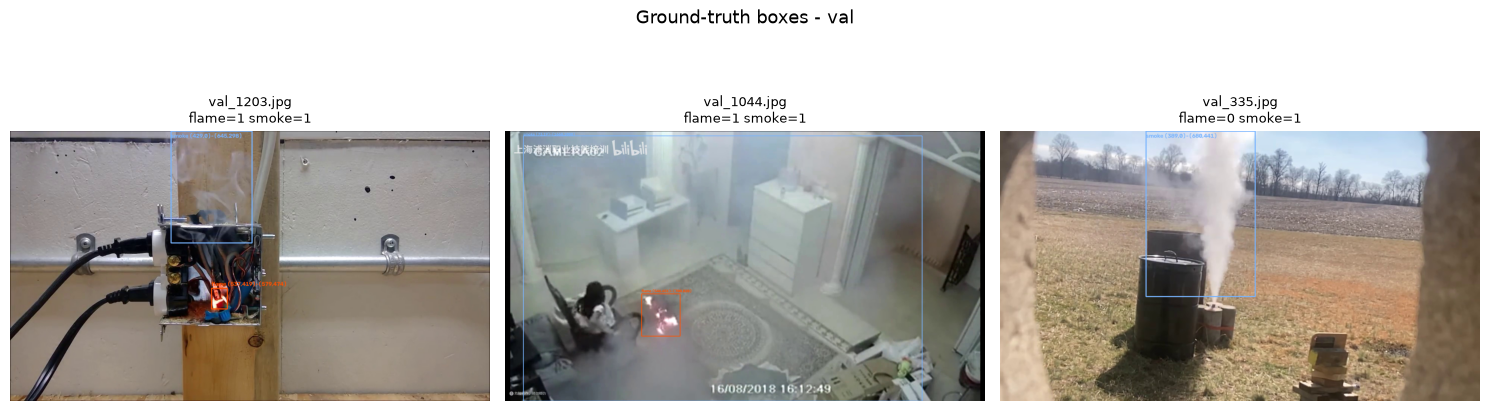

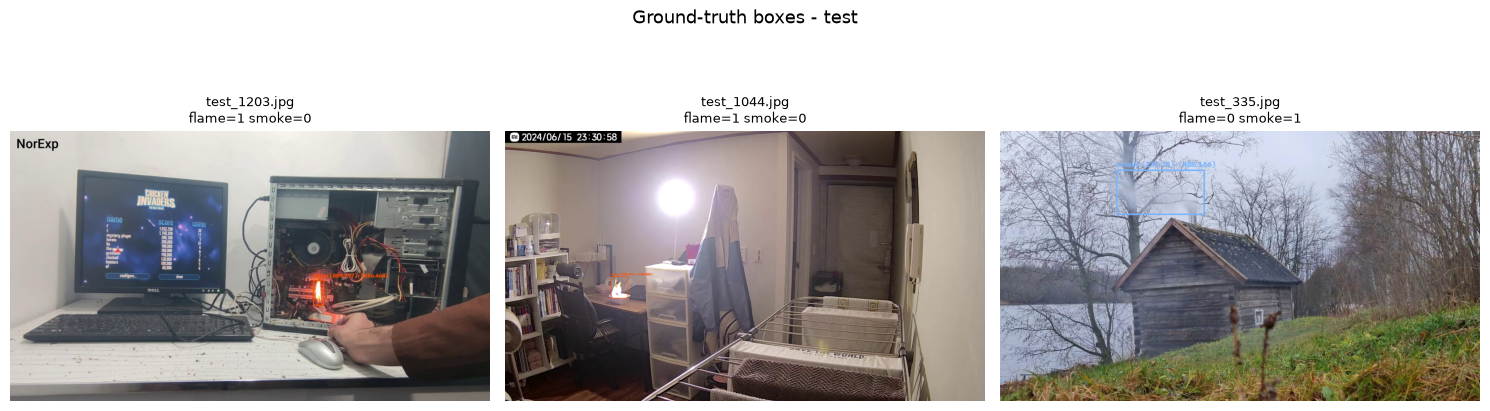

In [7]:
# Per-class colors (RGB). fire ~ red/orange, smoke ~ light blue.
COLORS = {0: (255, 80, 0), 1: (120, 180, 255)}

def load_ground_truth(image_path, label_path):
    """Decode a YOLO label into absolute pixel boxes for a given image.
    Returns (PIL_image, boxes) where each box = (cls_id, x1, y1, x2, y2)."""
    img = Image.open(image_path).convert("RGB")
    W, H = img.size
    boxes = []
    if Path(label_path).exists():
        for parts in parse_label_file(label_path):
            cid = int(float(parts[0]))
            cx, cy, w, h = map(float, parts[1:])
            x1 = int((cx - w / 2) * W); y1 = int((cy - h / 2) * H)
            x2 = int((cx + w / 2) * W); y2 = int((cy + h / 2) * H)
            boxes.append((cid, x1, y1, x2, y2))
    return img, boxes

def draw_boxes(img, boxes, class_names=CLASS_NAMES):
    """Draw boxes onto a copy of img; returns a numpy RGB array."""
    arr = np.array(img).copy()
    for cid, x1, y1, x2, y2 in boxes:
        color = COLORS.get(cid, (0, 255, 0))
        cv2.rectangle(arr, (x1, y1), (x2, y2), color, 2)
        label = f"{class_names.get(cid, cid)} ({x1},{y1})-({x2},{y2})"
        cv2.putText(arr, label, (x1, max(18, y1 - 6)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2, cv2.LINE_AA)
    return arr

def show_ground_truth(split="train", n=4, seed=SEED):
    imgs, _, _, lbl_dir = list_split(split)
    if not imgs:
        print("No images for", split); return
    rng = random.Random(seed)
    picks = rng.sample(imgs, min(n, len(imgs)))
    fig, axes = plt.subplots(1, len(picks), figsize=(5 * len(picks), 5))
    if len(picks) == 1:
        axes = [axes]
    for ax, ip in zip(axes, picks):
        lp = lbl_dir / (ip.stem + ".txt")
        img, boxes = load_ground_truth(ip, lp)
        ax.imshow(draw_boxes(img, boxes))
        n_fire  = sum(1 for b in boxes if b[0] == 0)
        n_smoke = sum(1 for b in boxes if b[0] == 1)
        ax.set_title(f"{ip.name}\nfire={n_fire} smoke={n_smoke}", fontsize=9)
        ax.axis("off")
    plt.suptitle(f"Ground-truth boxes - {split}", fontsize=13)
    plt.tight_layout()
    plt.show()

print("Ground-truth samples (fire = red, smoke = blue):")
for sp in ["train", "val", "test"]:
    show_ground_truth(sp, n=3)


## 7. Create `data.yaml`



In [8]:
def make_data_yaml(class_names, out_path, splits=("train", "val", "test")):
    """Write a portable YOLO data.yaml using paths relative to the YAML's own directory.

    Omitting the top-level 'path' key makes Ultralytics anchor every split on the
    directory that contains this YAML file, so the config works on any machine
    without hard-coding local absolute paths.
    """
    out_path = Path(out_path)
    cfg = {}
    for sp in splits:
        src = DATA_DIR / sp / "images"
        if src.is_dir():
            cfg[sp] = Path(os.path.relpath(src, out_path.parent)).as_posix()
    cfg["names"] = {int(k): v for k, v in class_names.items()}
    cfg["nc"] = len(class_names)
    out_path.parent.mkdir(parents=True, exist_ok=True)
    with open(out_path, "w", encoding="utf-8") as f:
        yaml.safe_dump(cfg, f, sort_keys=False)
    return cfg, out_path

cfg, cfg_path = make_data_yaml(CLASS_NAMES, DATA_YAML)
print("Wrote:", cfg_path)
print("-" * 40)
print(yaml.safe_dump(cfg, sort_keys=False).strip())
print("-" * 40)

# ---- Validate the config we just wrote ----
loaded = yaml.safe_load(open(cfg_path, "r", encoding="utf-8"))
ok = True
for key in ["train", "val"]:
    if key not in loaded:
        print(f"MISSING key '{key}' in data.yaml!"); ok = False
    else:
        d = DATA_DIR / key / "images"
        status = "OK" if d.is_dir() else "MISSING!"
        ok = ok and d.is_dir()
        print(f"  {key:5s} -> {d}  [{status}]")
if "test" in loaded:
    d = DATA_DIR / "test" / "images"
    print(f"  test  -> {d}  [{'OK' if d.is_dir() else 'MISSING'}]")
print("  names ->", loaded.get("names"))
print("\nConfig validation:", "PASSED" if ok else "FAILED")
DATA_YAML = cfg_path   # ensure later cells use the written file


Wrote: Home_Fire_YOLO\configs\data.yaml
----------------------------------------
path: Home_Fire_YOLO/data/home_fire
train: ./train/images
val: ./val/images
test: ./test/images
names:
  0: flame
  1: smoke
nc: 2
----------------------------------------
  train -> Home_Fire_YOLO\data\home_fire\train\images  [OK]
  val   -> Home_Fire_YOLO\data\home_fire\val\images  [OK]
  test  -> Home_Fire_YOLO\data\home_fire\test\images  [OK]
  names -> {0: 'flame', 1: 'smoke'}

Config validation: PASSED


## 8. Train YOLO



In [1]:
from ultralytics import YOLO

def get_device():
    return "0" if torch.cuda.is_available() else "cpu"

def train_model(run=True):
    """Fine-tune MODEL_NAME on DATA_YAML. Returns a dict, or None if skipped."""
    if not run:
        print("RUN_TRAINING is False -> skipping training.")
        print("Set RUN_TRAINING = True in the 'Configure paths' cell (Section 3) to train.")
        return None
    if not Path(DATA_YAML).exists():
        raise FileNotFoundError(f"{DATA_YAML} not found - run the data.yaml cell (Section 7) first.")
    device = get_device()
    print("Device:", device, "(GPU)" if device != "cpu" else "(CPU - expect this to be slow)")
    model = YOLO(MODEL_NAME)   # downloads pretrained weights on first use
    tag = f"{Path(MODEL_NAME).stem}_e{EPOCHS}_sz{IMG_SIZE}_b{BATCH_SIZE}_s{SEED}"
    run_name = f"homefire_{tag}"
    print("Starting training:", run_name)
    t0 = time.time()
    results = model.train(
        data=str(DATA_YAML),
        epochs=EPOCHS,
        imgsz=IMG_SIZE,
        batch=BATCH_SIZE,
        seed=SEED,
        device=device,
        workers=WORKERS,
        patience=PATIENCE,
        project=str(RUNS_DIR),
        name=run_name,
        exist_ok=False,
        verbose=True,
    )
    save_dir = Path(results.save_dir)
    best = save_dir / "weights" / "best.pt"
    last = save_dir / "weights" / "last.pt"
    print(f"\nTraining finished in {(time.time()-t0)/60:.1f} min.")
    print("Save dir :", save_dir)
    print("Best pt  :", best if best.exists() else "(not found)")
    print("Last pt  :", last if last.exists() else "(not found)")
    return {"results": results, "save_dir": save_dir, "best": best, "last": last}

TRAIN_OUT = train_model(RUN_TRAINING)


NameError: name 'RUN_TRAINING' is not defined

In [ ]:
# ---- Helper: locate the most recent best checkpoint (works even if training was
# ---- skipped in this session, e.g. from an earlier run that still lives in runs/) ----
def find_best_checkpoint():
    if TRAIN_OUT and TRAIN_OUT.get("best") and Path(TRAIN_OUT["best"]).exists():
        return Path(TRAIN_OUT["best"])
    cands = sorted(RUNS_DIR.glob("**/weights/best.pt"), key=lambda p: p.stat().st_mtime)
    if cands:
        return cands[-1]
    cands = sorted(list(MODELS_DIR.glob("*.pt")), key=lambda p: p.stat().st_mtime)
    return cands[-1] if cands else None

CKPT = find_best_checkpoint()
print("Using checkpoint:", CKPT if CKPT else "NONE (train first)")


## 9. Training visualization



In [ ]:
def _latest_results_csv():
    csvs = sorted(RUNS_DIR.glob("**/results.csv"), key=lambda p: p.stat().st_mtime)
    return csvs[-1] if csvs else None

def plot_training_results(run_dir=None):
    """Plot training losses & metrics from the run's results.csv."""
    if run_dir is None:
        csv_path = _latest_results_csv()
        if csv_path is None:
            print("No results.csv found - training has not run yet (Section 8).")
            return None
        run_dir = csv_path.parent
    csv_path = Path(run_dir) / "results.csv"
    if not csv_path.exists():
        print("results.csv not found in", run_dir); return None
    df = pd.read_csv(csv_path)
    df.columns = [c.strip() for c in df.columns]
    cols = set(df.columns)

    def pick(*names):
        for n in names:
            if n in cols:
                return n
        return None

    loss_map = {
        "Box loss":     [pick("train/box_loss"),  pick("val/box_loss")],
        "Class loss":   [pick("train/cls_loss"),  pick("val/cls_loss")],
        "DFL loss":     [pick("train/dfl_loss"),  pick("val/dfl_loss")],
    }
    metric_map = {
        "Precision":    [pick("metrics/precision(B)")],
        "Recall":       [pick("metrics/recall(B)")],
        "mAP@50":       [pick("metrics/mAP50(B)")],
        "mAP@50-95":    [pick("metrics/mAP50-95(B)")],
    }

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    # Losses
    ax = axes[0]
    plotted = False
    for title, (tr, va) in loss_map.items():
        if tr and tr in cols:
            ax.plot(df[tr], label=f"{title} (train)"); plotted = True
        if va and va in cols:
            ax.plot(df[va], "--", label=f"{title} (val)"); plotted = True
    ax.set_title("Training & validation losses"); ax.set_xlabel("Epoch"); ax.set_ylabel("Loss")
    if plotted: ax.legend()
    ax.grid(alpha=0.3)
    # Metrics
    ax = axes[1]
    plotted = False
    for title, series in metric_map.items():
        c = series[0]
        if c and c in cols:
            ax.plot(df[c], label=title); plotted = True
    ax.set_title("Validation metrics"); ax.set_xlabel("Epoch"); ax.set_ylabel("Score")
    ax.set_ylim(0, 1.05)
    if plotted: ax.legend()
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    # Also print the final-epoch values
    last = df.iloc[-1]
    print("Final epoch values:")
    for title, series in metric_map.items():
        c = series[0]
        if c and c in cols:
            print(f"   {title:12s}: {last[c]:.4f}")
    return df

RESULTS_DF = plot_training_results()


In [ ]:
# ---- If Ultralytics saved its own result images, display them too ----
def show_run_images(run_dir=None):
    if run_dir is None:
        csv_path = _latest_results_csv()
        run_dir = csv_path.parent if csv_path else None
    if run_dir is None:
        return
    for name in ["results.png", "confusion_matrix.png", "confusion_matrix_normalized.png",
                 "BoxF1_curve.png", "PR_curve.png", "P_curve.png", "R_curve.png"]:
        p = Path(run_dir) / name
        if p.exists():
            print("->", p.name)
            try:
                from IPython.display import display, Image as IPyImage
                display(IPyImage(filename=str(p)))
            except Exception:
                im = plt.imread(p); plt.figure(figsize=(8, 6)); plt.imshow(im); plt.axis("off"); plt.show()

show_run_images()


## 10. Model evaluation



In [ ]:
from ultralytics import YOLO

def evaluate_split(split_name, ckpt=None, conf=0.25):
    """Evaluate the model on a split ('val' or 'test'). Returns a metrics dict or None."""
    if ckpt is None:
        ckpt = find_best_checkpoint()
    if ckpt is None:
        print(f"[{split_name}] No trained checkpoint found - run training (Section 8) first.")
        return None
    model = YOLO(str(ckpt))
    print(f"[{split_name}] Evaluating {Path(ckpt).name} on the '{split_name}' split ...")
    metrics = model.val(data=str(DATA_YAML), split=split_name,
                        imgsz=IMG_SIZE, conf=conf, verbose=False)
    names = metrics.names
    box = metrics.box
    out = {
        "split": split_name,
        "checkpoint": str(ckpt),
        "precision": float(box.mp),
        "recall": float(box.mr),
        "mAP50": float(box.map50),
        "mAP50-95": float(box.map),
        "per_class": {},
    }
    # Per-class arrays
    p_arr, r_arr, ap50_arr, ap_arr = box.p, box.r, box.ap50, box.ap
    per_cls = {}
    for i, cname in names.items():
        per_cls[cname] = {
            "precision": float(p_arr[i]),
            "recall": float(r_arr[i]),
            "mAP50": float(ap50_arr[i]),
            "mAP50-95": float(ap_arr[i]),
        }
    out["per_class"] = per_cls
    # Confusion matrix (numpy array)
    try:
        cm = getattr(metrics, "confusion_matrix", None)
        if cm is not None and getattr(cm, "matrix", None) is not None:
            out["confusion_matrix"] = np.array(cm.matrix)
            out["cm_names"] = cm.names
    except Exception:
        pass
    print(f"[{split_name}] precision={out['precision']:.4f}  recall={out['recall']:.4f}  "
          f"mAP50={out['mAP50']:.4f}  mAP50-95={out['mAP50-95']:.4f}")
    return out

def print_eval_report(res):
    if res is None:
        print("  (no results)"); return
    print(f"\n=== {res['split'].upper()} SPLIT ===")
    print(f"  Checkpoint   : {Path(res['checkpoint']).name}")
    print(f"  Precision    : {res['precision']:.4f}")
    print(f"  Recall       : {res['recall']:.4f}")
    print(f"  mAP@50       : {res['mAP50']:.4f}")
    print(f"  mAP@50-95    : {res['mAP50-95']:.4f}")
    print("  Per-class:")
    for cname, m in res["per_class"].items():
        print(f"     {cname:8s} P={m['precision']:.3f} R={m['recall']:.3f} "
              f"mAP50={m['mAP50']:.3f} mAP50-95={m['mAP50-95']:.3f}")

def plot_confusion_matrix(res, normalize=True):
    if res is None or "confusion_matrix" not in res:
        print("  (no confusion matrix available)"); return
    cm = res["confusion_matrix"].astype(float)
    names = res.get("cm_names", CLASS_NAMES)
    labels = [names[i] for i in sorted(names.keys())] if isinstance(names, dict) else list(names)
    disp = cm.copy()
    if normalize:
        row_sum = disp.sum(axis=1, keepdims=True)
        row_sum[row_sum == 0] = 1
        disp = disp / row_sum
    fig, ax = plt.subplots(figsize=(5, 4))
    im = ax.imshow(disp, cmap="Blues")
    ax.set_xticks(range(len(labels))); ax.set_yticks(range(len(labels)))
    ax.set_xticklabels(labels); ax.set_yticklabels(labels)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    ax.set_title(("Normalized " if normalize else "") + "Confusion matrix")
    for i in range(disp.shape[0]):
        for j in range(disp.shape[1]):
            val = disp[i, j]
            ax.text(j, i, f"{val:.2f}" if normalize else f"{int(val)}",
                    ha="center", va="center",
                    color="white" if val > disp.max() / 2 else "black", fontsize=9)
    plt.colorbar(im)
    plt.tight_layout()
    plt.show()

# ---- Validation split ----
VAL_METRICS = evaluate_split("val")
print_eval_report(VAL_METRICS)


In [ ]:
# ---- Held-out TEST split (evaluated once, separately - never used for tuning) ----
TEST_METRICS = evaluate_split("test")
print_eval_report(TEST_METRICS)


In [ ]:
# ---- Visualize confusion matrices (validation, then test) ----
if VAL_METRICS is not None:
    print("Validation split:")
    plot_confusion_matrix(VAL_METRICS, normalize=True)
if TEST_METRICS is not None:
    print("Test split:")
    plot_confusion_matrix(TEST_METRICS, normalize=True)


## 11. Single-image prediction



In [ ]:
def predict_single(image_path, conf=CONF_THRESH, ckpt=None, show=True):
    """Run inference on one image. Returns the list of detections."""
    if ckpt is None:
        ckpt = find_best_checkpoint()
    if ckpt is None:
        print("No trained checkpoint found - train first (Section 8)."); return None
    image_path = Path(image_path)
    if not image_path.exists():
        print("Image not found:", image_path); return None
    model = YOLO(str(ckpt))
    results = model.predict(source=str(image_path), conf=conf,
                            imgsz=IMG_SIZE, verbose=False)
    r = results[0]
    names = r.names
    dets = []
    if r.boxes is not None and len(r.boxes) > 0:
        for b in r.boxes:
            cid = int(b.cls.item())
            conf_v = float(b.conf.item())
            x1, y1, x2, y2 = [float(v) for v in b.xyxy[0].tolist()]
            dets.append(dict(class_id=cid, class_name=names[cid], confidence=conf_v,
                             x1=x1, y1=y1, x2=x2, y2=y2))
    if show:
        fig, axes = plt.subplots(1, 2, figsize=(14, 6))
        axes[0].imshow(Image.open(image_path).convert("RGB"))
        axes[0].set_title(f"Original: {image_path.name}"); axes[0].axis("off")
        axes[1].imshow(r.plot()[:, :, ::-1])   # r.plot() returns BGR
        axes[1].set_title(f"Annotated (conf >= {conf})"); axes[1].axis("off")
        plt.tight_layout(); plt.show()
        print(f"Image      : {image_path}")
        print(f"Confidence : >= {conf}")
        print(f"Detections : {len(dets)}")
        if dets:
            for i, d in enumerate(dets, 1):
                print(f"   {i}. {d['class_name']:6s} conf={d['confidence']:.3f} "
                      f"box=({d['x1']:.0f},{d['y1']:.0f})-({d['x2']:.0f},{d['y2']:.0f})")
        else:
            print("   No objects detected above the threshold.")
    return dets

# ---- Choose an image (edit this to point at your own file) ----
_, test_imgs, _, _ = list_split("test")
PRED_IMAGE_PATH = test_imgs[0] if test_imgs else None   # e.g. r"C:\path\to\my_photo.jpg"
CONF = CONF_THRESH                                      # adjustable threshold

print("Predicting on:", PRED_IMAGE_PATH)
SINGLE_DETS = predict_single(PRED_IMAGE_PATH, conf=CONF)


## 12. Batch prediction



In [ ]:
def predict_batch(input_dir=None, split="test", conf=CONF_THRESH, ckpt=None,
                  out_dir=None, csv_name=None, max_images=None):
    """Batch inference. Saves annotated images + a CSV report. Returns the DataFrame."""
    if ckpt is None:
        ckpt = find_best_checkpoint()
    if ckpt is None:
        print("No trained checkpoint found - train first (Section 8)."); return None
    if input_dir is None:
        input_dir = DATA_DIR / split / "images"
    input_dir = Path(input_dir)
    if not input_dir.is_dir():
        print("Input directory not found:", input_dir); return None
    out_dir = Path(out_dir) if out_dir else PRED_DIR
    out_dir.mkdir(parents=True, exist_ok=True)
    imgs = sorted([p for p in input_dir.iterdir() if p.suffix.lower() in IMG_EXTS])
    if max_images:
        imgs = imgs[:max_images]
    print(f"Running batch inference on {len(imgs)} images from {input_dir}")
    model = YOLO(str(ckpt))
    rows = []
    for i, ip in enumerate(imgs, 1):
        res = model.predict(source=str(ip), conf=conf, imgsz=IMG_SIZE, verbose=False)[0]
        n = len(res.boxes) if res.boxes is not None else 0
        if n > 0:
            # Save the annotated frame
            annotated = res.plot()
            cv2.imwrite(str(out_dir / f"{ip.stem}_pred.jpg"), annotated)
            for b in res.boxes:
                cid = int(b.cls.item())
                conf_v = float(b.conf.item())
                x1, y1, x2, y2 = [float(v) for v in b.xyxy[0].tolist()]
                rows.append(dict(image=ip.name, class_id=cid,
                                 class_name=res.names[cid], confidence=round(conf_v, 4),
                                 x1=round(x1, 1), y1=round(y1, 1),
                                 x2=round(x2, 1), y2=round(y2, 1)))
        else:
            rows.append(dict(image=ip.name, class_id="", class_name="",
                             confidence="", x1="", y1="", x2="", y2=""))
        if i % 100 == 0:
            print(f"   processed {i}/{len(imgs)}")
    rep_dir = Path(REPORT_DIR); rep_dir.mkdir(parents=True, exist_ok=True)
    csv_name = csv_name or f"batch_predictions_{split}.csv"
    csv_path = rep_dir / csv_name
    df = pd.DataFrame(rows)
    df.to_csv(csv_path, index=False)
    n_det = int((df["class_name"] != "").sum()) if len(df) else 0
    print(f"\nDone. {len(imgs)} images processed, {n_det} detections total.")
    print("Annotated images ->", out_dir)
    print("CSV report       ->", csv_path)
    return df

BATCH_DF = predict_batch(split="test", conf=CONF_THRESH, max_images=200)
if BATCH_DF is not None:
    display_df = BATCH_DF.head(15)
    try:
        from IPython.display import display
        display(display_df)
    except Exception:
        print(display_df.to_string(index=False))


## 13. Save & export



In [ ]:
def export_artifacts(ckpt=None, val_res=None, test_res=None, export_onnx=False):
    """Copy checkpoints/charts/metrics into models/ and outputs/reports/."""
    ckpt = ckpt or find_best_checkpoint()
    if ckpt is None:
        print("No checkpoint to export - train first (Section 8).")
    else:
        stamp = time.strftime("%Y%m%d-%H%M%S")
        dest_ts = MODELS_DIR / f"best_{Path(ckpt).stem}_{stamp}.pt"
        dest_plain = MODELS_DIR / "best.pt"
        shutil.copy2(ckpt, dest_ts)
        shutil.copy2(ckpt, dest_plain)
        print("Copied best checkpoint ->", dest_ts)
        print("Copied best checkpoint ->", dest_plain)

    rep = Path(REPORT_DIR); rep.mkdir(parents=True, exist_ok=True)
    # Copy run charts
    csv_path = _latest_results_csv()
    if csv_path:
        run_dir = csv_path.parent
        for name in ["results.png", "results.csv", "confusion_matrix.png",
                     "confusion_matrix_normalized.png", "PR_curve.png", "BoxF1_curve.png"]:
            p = run_dir / name
            if p.exists():
                shutil.copy2(p, rep / name)
                print("Copied report file ->", rep / name)

    # Combined metrics JSON + per-class CSV
    metrics_blob = {"val": val_res, "test": test_res,
                    "config": {"model": MODEL_NAME, "epochs": EPOCHS, "imgsz": IMG_SIZE,
                               "batch": BATCH_SIZE, "seed": SEED, "device": DEVICE}}
    json_path = rep / "metrics.json"
    with open(json_path, "w", encoding="utf-8") as f:
        json.dump(metrics_blob, f, indent=2)
    print("Wrote metrics JSON ->", json_path)

    rows = []
    for res in (val_res, test_res):
        if not res: continue
        for cname, m in res["per_class"].items():
            rows.append(dict(split=res["split"], class_name=cname, **m))
    if rows:
        pc_csv = rep / "per_class_metrics.csv"
        pd.DataFrame(rows).to_csv(pc_csv, index=False)
        print("Wrote per-class CSV ->", pc_csv)

    # Optional ONNX export
    if export_onnx and ckpt is not None:
        try:
            model = YOLO(str(ckpt))
            onnx_path = model.export(format="onnx", imgsz=IMG_SIZE)
            print("Exported ONNX ->", onnx_path)
        except Exception as e:
            print("ONNX export failed (is the 'onnx' package installed?):", e)
    return ckpt

EXPORT_ONNX = False   # set True to also export an ONNX model
EXPORTED_CKPT = export_artifacts(ckpt=find_best_checkpoint(),
                                 val_res=VAL_METRICS, test_res=TEST_METRICS,
                                 export_onnx=EXPORT_ONNX)


## 14. Final summary



In [ ]:
def print_final_summary():
    print("=" * 70)
    print("FINAL SUMMARY - Home Fire & Smoke Detection (YOLO)")
    print("=" * 70)

    # Dataset
    total = EXPLORATION["total_images"] if 'EXPLORATION' in globals() else None
    print("\n[Dataset]")
    print("  Source            : Home Fire Dataset (Kaggle: pengbo00/home-fire-dataset)")
    print("  Format            : YOLO TXT (class cx cy w h, normalized)")
    print("  Classes           :", CLASS_NAMES)
    if total is not None:
        print("  Total images      :", total)
        for sp in SPLITS:
            s = EXPLORATION["scan"][sp]
            print(f"     {sp:5s}: {s['images']} images, {s['labels']} labels, "
                  f"{s['empty_label_files']} empty (background)")
    print("  Cleanliness       : 0 missing labels, 0 corrupt images, 0 invalid boxes, "
          "0 cross-split leakage")

    # Config
    print("\n[Training configuration]")
    print(f"  Model             : {MODEL_NAME}")
    print(f"  Epochs            : {EPOCHS}")
    print(f"  Image size        : {IMG_SIZE}")
    print(f"  Batch size        : {BATCH_SIZE}")
    print(f"  Seed              : {SEED}")
    print(f"  Device            : {DEVICE}")

    # Checkpoint
    ckpt = find_best_checkpoint()
    print("\n[Best checkpoint]")
    print("  Path              :", ckpt if ckpt else "NONE (training has not run)")
    if ckpt and ckpt.exists():
        print(f"  Size              : {ckpt.stat().st_size/1e6:.1f} MB")

    # Results
    print("\n[Actual evaluation results]")
    for label, res in [("Validation", VAL_METRICS), ("Test", TEST_METRICS)]:
        if res is None:
            print(f"  {label:10s}: (not evaluated - train first)")
        else:
            print(f"  {label:10s}: P={res['precision']:.4f}  R={res['recall']:.4f}  "
                  f"mAP50={res['mAP50']:.4f}  mAP50-95={res['mAP50-95']:.4f}")
            for cname, m in res["per_class"].items():
                print(f"        {cname:6s} P={m['precision']:.3f} R={m['recall']:.3f} "
                      f"mAP50={m['mAP50']:.3f} mAP50-95={m['mAP50-95']:.3f}")

    print("\n[Known limitations]")
    print("  - Indoor / home-surveillance data only; expect weaker generalization to")
    print("    outdoor wildfires or very different cameras.")
    print("  - Smoke is wispy and hard to bound tightly, so smoke mAP is usually lower")
    print("    than fire mAP.")
    print("  - 135 background (empty) images are kept on purpose to suppress false")
    print("    positives, so not every image contains a target.")
    print("  - Results depend on hardware, epochs, and seed; numbers above are from THIS run.")
    print("\nOutputs:")
    print("  models/               best checkpoint(s)")
    print("  outputs/reports/      metrics.json, per-class CSV, charts, confusion matrix")
    print("  outputs/predictions/  annotated prediction images")
    print("  runs/                 full Ultralytics training runs")
    print("=" * 70)

print_final_summary()
